# Fitting the galaxy&ndash;halo connection at cosmic dawn with `halogal.inference`

### An injection&ndash;recovery tutorial: UVLF vs. angular clustering vs. the two jointly

**Euclid Primordial Universe working group &mdash; hands-on session**

---

At $z \sim 5$&ndash;$6$ we watch the first galaxies light up inside dark-matter
haloes. Two observables give us almost orthogonal handles on the
**galaxy&ndash;halo connection**:

- The **UV luminosity function** $\Phi(M_{\rm UV})$ &mdash; *how many* galaxies
  there are at each brightness. It pins down the **abundance** of galaxies and
  hence the **star-formation efficiency** (SFE): how effectively a halo of a
  given mass converts accreted gas into UV photons.
- The **angular two-point clustering** $w(\theta)$ &mdash; *how strongly*
  galaxies cluster on the sky. Clustering amplitude is set by the **halo bias**,
  which is a near-monotonic function of **halo mass**. So $w(\theta)$ tells us
  *which haloes* a given galaxy population lives in.

These two probes are **complementary**. The UVLF constrains the
amplitude/shape of the SFE but is degenerate between "many faint galaxies in
small haloes" and "fewer bright galaxies in bigger haloes". Clustering breaks
that degeneracy by measuring the host halo mass directly &mdash; but on its own
it says little about the overall normalisation of the SFE. The natural question,
and the scientific punchline of this tutorial, is:

> **How much better are the galaxy&ndash;halo parameters constrained when we fit
> the UVLF and $w(\theta)$ *jointly*, compared to either alone?**

This is exactly the regime Euclid opens up: wide-area, high-$z$ samples where
both a well-measured UVLF *and* a clustering signal are within reach, so a joint
analysis is not a luxury but the default. Understanding the complementarity now
&mdash; on controlled mock data where we know the truth &mdash; tells us what to
expect from the real primordial-universe measurements.

**What we will do (injection&ndash;recovery):**
1. Take a known "truth" (the published `DEFAULT_HOD_PARAMS` at $z = 5.4$).
2. Simulate a mock UVLF *and* a mock $w(\theta)$ from that truth, with realistic
   noise.
3. Fit three cases with identical sampler settings &mdash; **UVLF only**,
   **$w(\theta)$ only**, **joint** &mdash; and see how well each recovers the
   input parameters.
4. Compare the posteriors and discuss the degeneracy directions.

We use the `halogal.inference` module, which exposes `emcee` and `dynesty`
behind one interface.

## 1. Installation

> *This section is reference only &mdash; if you are running this notebook you
> have already done it. Nothing here needs to be executed.*

```bash
# 1. Clone the repository
git clone https://github.com/<org>/uvlf-hod.git
cd uvlf-hod

# 2. Check out the inference branch (the MCMC module lives here)
git checkout inference

# 3. Create the environment from environment.yml.
#    We pin numpy<2 because numba (used in the hot loops of the forward model)
#    needs an ABI-compatible numpy; mixing numpy 2.x with the numba build in
#    the stack leads to import-time crashes.
micromamba create -f environment.yml     # or: mamba env create -f environment.yml
micromamba activate halogal

# 4. Install halogal itself in editable mode
pip install -e .
```

The stack this notebook relies on: `numpy 1.26.4`, `camb`, `hmf`, `halomod`,
`numba`, `emcee`, `dynesty`, `corner`.

### Imports and plot style

We add the repository root and the `examples/` directory to `sys.path` so the
notebook works regardless of where the kernel was launched. The plotting style
`marko.mplstyle` is optional &mdash; we fall back gracefully if it is not
installed.

In [2]:
import warnings
warnings.filterwarnings("ignore")  # keep the tutorial output clean

import os
import sys
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Make halogal and the examples/ helpers importable from any launch directory.
REPO = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "examples" else os.getcwd()
for p in (REPO, os.path.join(REPO, "examples")):
    if p not in sys.path:
        sys.path.insert(0, p)

# Plot style: try the installed name, then the matplotlib config dir, then skip.
def _use_marko_style():
    import matplotlib
    for cand in ("marko.mplstyle",
                 os.path.join(matplotlib.get_configdir(), "marko.mplstyle")):
        try:
            plt.style.use(cand)
            return True
        except OSError:
            continue
    return False

if not _use_marko_style():
    print("marko.mplstyle not found; using matplotlib defaults.")

%matplotlib inline
print("Imports OK. numpy", np.__version__)

Missing colon in file '/Users/mshuntov/.matplotlib/marko.mplstyle', line 38 ("    '0072B2',")
Missing colon in file '/Users/mshuntov/.matplotlib/marko.mplstyle', line 39 ("    'D55E00',")
Missing colon in file '/Users/mshuntov/.matplotlib/marko.mplstyle', line 40 ("    '009E73',")
Missing colon in file '/Users/mshuntov/.matplotlib/marko.mplstyle', line 41 ("    'CC79A7',")
Missing colon in file '/Users/mshuntov/.matplotlib/marko.mplstyle', line 42 ("    'F0E442',")
Missing colon in file '/Users/mshuntov/.matplotlib/marko.mplstyle', line 43 ("    '56B4E9',")
Missing colon in file '/Users/mshuntov/.matplotlib/marko.mplstyle', line 44 ("    'E69F00',")
Missing colon in file '/Users/mshuntov/.matplotlib/marko.mplstyle', line 45 ("    '000000'])")
Bad value in file '/Users/mshuntov/.matplotlib/marko.mplstyle', line 37 ("axes.prop_cycle : cycler('color', ["): Key axes.prop_cycle: "cycler('color', [" is not a valid cycler construction: Could not parse "cycler('color', [": '[' was never closed

Imports OK. numpy 1.26.4


### Configuration

Everything the presenter might want to tweak lives here. The two knobs that
control wall time are `NWALKERS` and `NSTEPS`; **lower `NSTEPS` to save time**
during a live session (the contours get noisier but the *relative* comparison
between the three fits is preserved). All three emcee fits use the **same**
chain size for a fair comparison.

Benchmarked on a 12-core machine:
- one UVLF likelihood call &approx; 0.015 s &rarr; a UVLF-only fit is seconds;
- one clustering likelihood call &approx; 0.55 s &rarr; each clustering fit
  &approx; `16 s + NWALKERS*NSTEPS*0.57/NPROC` s
  (&approx; **3.7 min** at 22&times;180 on 11 processes).

In [52]:
# ---- Physical / observational setup (benchmarked; do not change lightly) ----
Z = 5.4                                   # single-redshift fit
MUV_THRESH = -21.0                        # magnitude threshold for clustering

# Redshift distribution p(z) entering the angular projection of w(theta).
# MUST be picklable for the parallel (processes=) path -> use a frozen
# scipy distribution's bound .pdf method, NEVER a lambda.
pz = norm(loc=Z, scale=0.3)               # simple Gaussian centred on Z
CORR = dict(correlation_type="angular", p1=pz.pdf, znum=20, theta_num=20)

# Data abscissae
MUV = np.linspace(-23.5, -17, 14)                       # UVLF magnitude grid
theta = np.logspace(np.log10(1.5), np.log10(6000.0), 12)  # w(theta) grid [arcsec]

# Halo mass function grid resolution for the forward model.
HMF_POINTS = 256

# Parallelism: leave one core free for the OS / notebook.
NPROC = max(1, os.cpu_count() - 1)

# Reproducibility
SEED = 1

# --- SMOKE-TEST VALUES (scaled down) ---
NWALKERS = 20
NSTEPS   = 1000
DYNESTY_NLIVE   = 30
DYNESTY_MAXCALL = 3000

# Where to back up the live chains.
CHAIN_DIR = os.path.join(REPO, "examples", "tutorial_chains")
os.makedirs(CHAIN_DIR, exist_ok=True)

print(f"Z={Z}, NPROC={NPROC}, NWALKERS={NWALKERS}, NSTEPS={NSTEPS}")
print(f"Chains will be backed up to: {CHAIN_DIR}")

Z=5.4, NPROC=11, NWALKERS=20, NSTEPS=1000
Chains will be backed up to: /Users/mshuntov/CodeWorks/uvlf-hod/examples/tutorial_chains


## 2. Forward-model recap

Before fitting anything, a two-minute reminder of the forward model (condensed
from `examples/basic_usage.ipynb`, Parts 1&ndash;2). An `HODModel` bundles the
UV&ndash;halo-mass relation and the halo-occupation distribution; an
`Observables` object turns it into predictions.

In [35]:
from halogal import HODModel
from halogal.model import Observables
from halogal.config import DEFAULT_HOD_PARAMS as HP

# Build the model at our redshift using the published best-fit parameters.
model = HODModel(
    z=Z,
    eps0=HP["eps0"],          # star-formation efficiency normalisation
    Mc=10**HP["logMc"],       # characteristic halo mass [M_sun] (linear!)
    a=HP["a"],                # low-mass slope
    b=HP["b"],                # high-mass slope
    sigma_UV=HP["sigma_UV"],  # UV magnitude scatter [mag]
    add_dust=True,
)
obs = Observables(model)
print(model)

HOD Model at z=5.4
UVHMR Parameters:
  eps0 = 0.190
  Mc = 4.37e+11 M_sun
  a = 0.69
  b = 0.65

HOD Parameters:
  sigma_UV = 0.69 mag
  Mcut = 3.72e+09 M_sun
  Msat = 4.47e+12 M_sun
  asat = 0.85

Settings:
  add_dust = True


Two fiducial predictions: the UVLF over our magnitude grid, and the angular
correlation function $w(\theta)$ for galaxies brighter than
$M_{\rm UV} < -20$. Note the initialise-once / update-many pattern for
clustering &mdash; the expensive `halomod` setup happens in
`initialize_correlation_model`, and the cheap `update_correlation_model` reuses
it. This is exactly what makes the MCMC affordable.

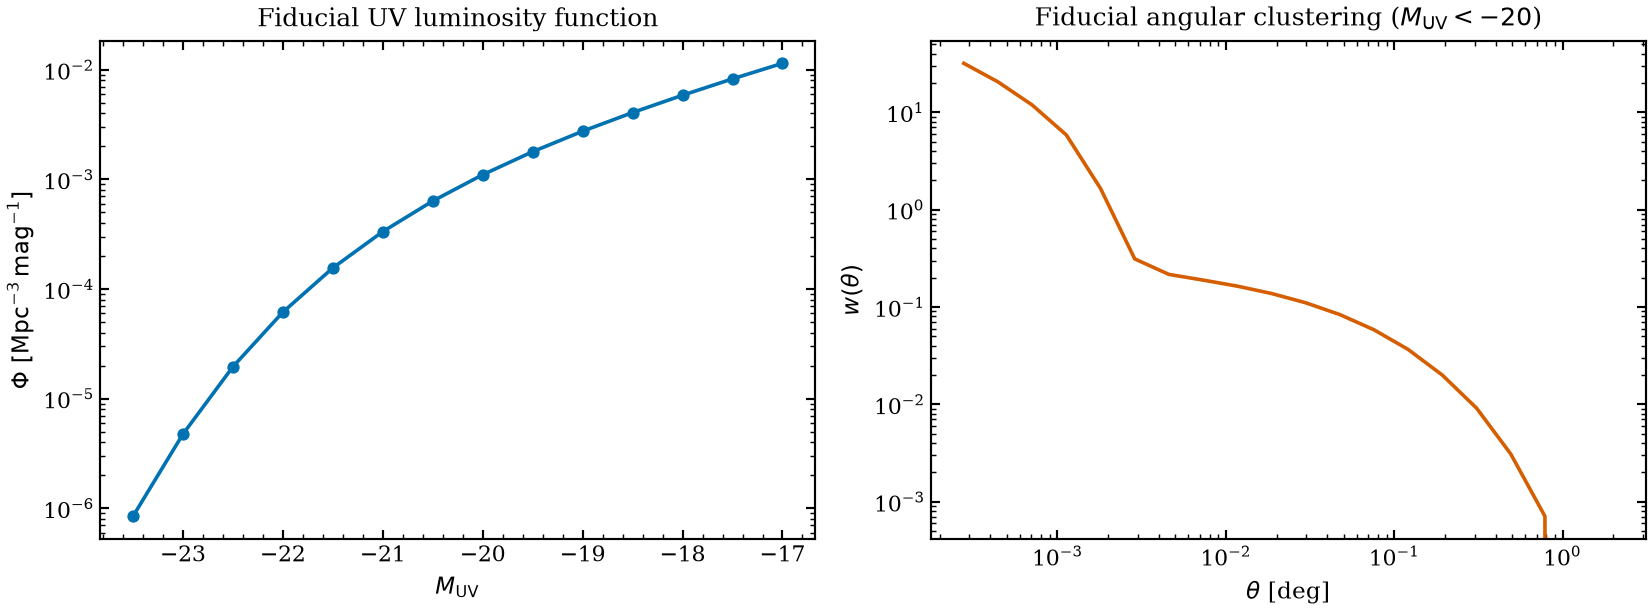

In [36]:
# UVLF at fiducial parameters
phi_fid = obs.luminosity_function(MUV)

# w(theta) at fiducial parameters (initialise the halomod model once)
obs.initialize_correlation_model(MUV_thresh1=MUV_THRESH, **CORR)
cf = obs.update_correlation_model()
theta_model, w_model = cf["separation"], cf["correlation"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.semilogy(MUV, phi_fid, "o-", color="#0072B2")
ax1.set_xlabel(r"$M_{\rm UV}$")
ax1.set_ylabel(r"$\Phi\ [\mathrm{Mpc}^{-3}\,\mathrm{mag}^{-1}]$")
ax1.set_title("Fiducial UV luminosity function")

ax2.loglog(theta_model/3600, w_model, "-", color="#D55E00")
ax2.set_xlabel(r"$\theta$ [deg]")
ax2.set_ylabel(r"$w(\theta)$")
ax2.set_title(r"Fiducial angular clustering ($M_{\rm UV} < -20$)")

plt.tight_layout()
plt.show()

## 3. The inference building blocks

`halogal.inference` is a small pipeline of layers. A sampler only ever sees a
flat vector `theta`; a mapping layer turns it into named parameters, and a
parametrization layer turns those into the per-redshift HOD parameters the model
consumes. Let us meet the pieces with tiny snippets.

In [6]:
from halogal.inference import (
    Parameter, ParameterSet, Uniform, Normal,
    ModelParametrization, Dataset, GaussianLikelihood,
    EmceeSampler, DynestySampler, InferenceResult,
)

### 3a. Parameters and priors

A `Parameter` has a name, an optional prior, and can be `fixed`. A
`ParameterSet` aggregates the free ones and owns the `theta` &harr; named-dict
mapping. Priors (`Uniform(low, high)`, `Normal(mu, sigma)`) define their
behaviour for *both* backends at once.

We fit the **five SFE / UV&ndash;halo-mass parameters**
(`eps0, logMc, a, b, sigma_UV`) and leave the satellite parameters
(`logMcut, logMsat, asat`) at their config defaults. **Masses are sampled in
$\log_{10}$** &mdash; that is what the `logMc` name means.

In [37]:
def make_parameter_set():
    return ParameterSet([
        Parameter("eps0",     Uniform(0.02, 0.40)),
        Parameter("logMc",    Uniform(10.5, 12.5)),   # log10(Mc / M_sun)
        Parameter("a",        Uniform(0.20, 1.20)),
        Parameter("b",        Uniform(0.20, 1.50)),
        Parameter("sigma_UV", Uniform(0.20, 1.30)),
    ])

pset_demo = make_parameter_set()
print("free names :", pset_demo.names)
print("ndim       :", pset_demo.ndim)
print("to_dict at a test theta:",
      pset_demo.to_dict([0.19, 11.64, 0.69, 0.65, 0.69]))

free names : ['eps0', 'logMc', 'a', 'b', 'sigma_UV']
ndim       : 5
to_dict at a test theta: {'eps0': 0.19, 'logMc': 11.64, 'a': 0.69, 'b': 0.65, 'sigma_UV': 0.69}


### 3b. Datasets (covariance-aware)

A `Dataset` holds one observable at one redshift together with its covariance.
The Cholesky factor is computed once at construction, so each likelihood call is
a single back-substitution. Here we pass a diagonal `sigma`; the API also
accepts a full `cov` matrix (see the wrap-up).

- `Dataset.uvlf(z, MUV, phi, sigma=...)`
- `Dataset.clustering(z, theta, w, sigma=..., MUV_thresh1=..., corr_kwargs=...)`

We construct the real datasets in Section 4.

### 3c. Model parametrization

`ModelParametrization("fixed_z", parameter_set)` picks the single-redshift
regime and, crucially, owns the **$\log_{10}\rightarrow$ linear mass**
conversion at the boundary just before the model is called. Parameters *not* in
the set fall back to the config defaults &mdash; this is how the satellite
parameters stay fixed at their published values without us listing them.

In [38]:
mp = ModelParametrization("fixed_z", make_parameter_set())
# What the model actually receives at a given theta (note Mc is now LINEAR):
named = make_parameter_set().to_dict([0.19, 11.64, 0.69, 0.65, 0.69])
print(mp.params_for_redshift(named, Z))

{'eps0': 0.19, 'Mc': 436515832240.16656, 'a': 0.69, 'b': 0.65, 'sigma_UV': 0.69, 'Mcut': 3715352290.971728, 'Msat': 4466835921509.635, 'asat': 0.85}


### 3d. Likelihood and sampler

`GaussianLikelihood(datasets, parametrization, hmf_points=256)` composes the
datasets into one total log-likelihood, builds one `Observables` per redshift
bin, and initialises the clustering model once per bin. `.check()` runs a quick
self-consistency test. `EmceeSampler(parameter_set, likelihood).run(...)` drives
the affine-invariant ensemble sampler; `processes=` parallelises across cores
(the likelihood pickles cleanly and rebuilds the `halomod` state in each
worker &mdash; which is why `p1=pz.pdf` must be picklable).

We assemble concrete likelihoods next.

## 4. Simulate the mock data from a known truth

The heart of an injection&ndash;recovery test: we generate the "data" ourselves
from a known truth, add realistic noise, and later check whether the fits find
their way back.

**Truth** = the published `DEFAULT_HOD_PARAMS` mapped onto our five fitted
names.

In [39]:
truth = dict(
    eps0=HP["eps0"],
    logMc=HP["logMc"],
    a=HP["a"],
    b=HP["b"],
    sigma_UV=HP["sigma_UV"],
)
print("Injected truth:", truth)

Injected truth: {'eps0': 0.19, 'logMc': 11.64, 'a': 0.69, 'b': 0.65, 'sigma_UV': 0.69}


### The redshift distribution $p(z)$

The angular clustering $w(\theta)$ is a projection of the 3-D correlation
function through the sample's redshift distribution $p(z)$. We use a simple
Gaussian centred on $z = 5.4$ (defined in the CONFIG cell as `pz`) and use the
**same** $p(z)$ to simulate and to fit &mdash; so any recovery failure is about
the parameters, not a projection mismatch.

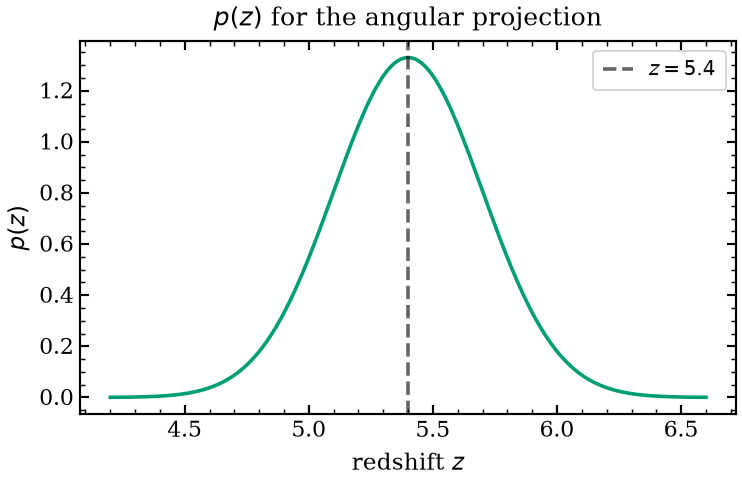

In [40]:
zz = np.linspace(Z - 1.2, Z + 1.2, 200)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(zz, pz.pdf(zz), color="#009E73")
ax.axvline(Z, ls="--", color="k", alpha=0.6, label=f"$z={Z}$")
ax.set_xlabel("redshift $z$")
ax.set_ylabel("$p(z)$")
ax.set_title(r"$p(z)$ for the angular projection")
ax.legend()
plt.tight_layout()
plt.show()

### Generate noiseless truth curves, then add noise

We reuse a single `ModelParametrization` to map the truth dict to model space,
evaluate both observables, and add **diagonal** noise:

- UVLF: $\sigma_\Phi = 0.15\,\Phi_{\rm true} + 10^{-6}$ (15% + a small floor);
- $w(\theta)$: $\sigma_w = 0.25\,|w_{\rm true}| + 0.005\,\max|w_{\rm true}|$.

The RNG is seeded so the mock is reproducible.

In [49]:
mp_truth = ModelParametrization("fixed_z")   # no set -> pure defaults + overrides
truth_model_params = mp_truth.params_for_redshift(dict(truth), Z)

# --- noiseless UVLF ---
obs_sim = Observables(HODModel(z=Z))
phi_true = np.atleast_1d(obs_sim.luminosity_function(MUV, **truth_model_params))

# --- noiseless w(theta) ---
obs_sim.initialize_correlation_model(MUV_thresh1=MUV_THRESH, **CORR)
res = obs_sim.update_correlation_model(**truth_model_params)
w_true = np.interp(np.log10(theta),
                   np.log10(res["separation"]), res["correlation"])

# --- add reproducible diagonal noise ---
rng = np.random.default_rng(SEED)
uvlf_sigma = 0.15 * phi_true + 1e-7
phi_obs = phi_true + uvlf_sigma * rng.standard_normal(len(MUV))

w_sigma = 0.25 * np.abs(w_true) + 0.001 * np.max(np.abs(w_true))
w_obs = w_true + w_sigma * rng.standard_normal(len(theta))

print("mock UVLF and w(theta) generated.")

mock UVLF and w(theta) generated.


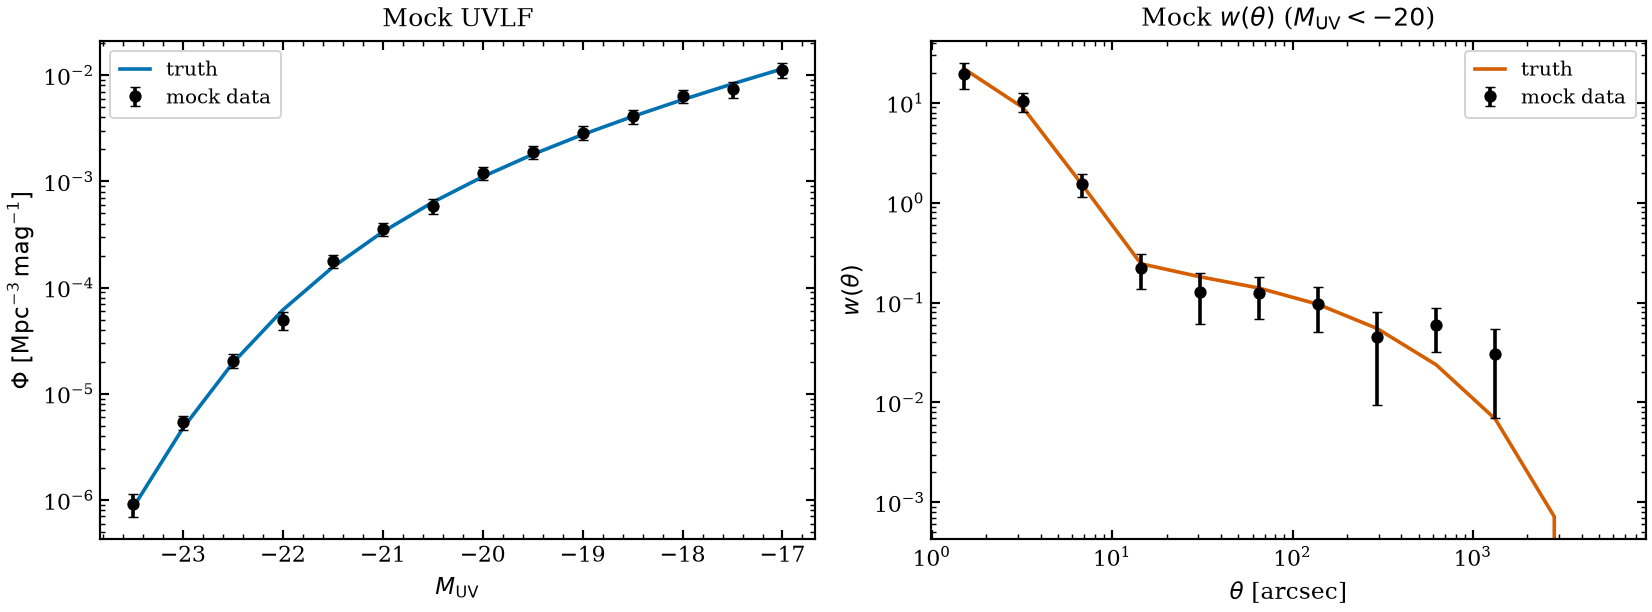

In [50]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(MUV, phi_true, "-", color="#0072B2", label="truth")
ax1.errorbar(MUV, phi_obs, yerr=uvlf_sigma, fmt="o", color="k",
             capsize=3, label="mock data")
ax1.set_yscale("log")
ax1.set_xlabel(r"$M_{\rm UV}$")
ax1.set_ylabel(r"$\Phi\ [\mathrm{Mpc}^{-3}\,\mathrm{mag}^{-1}]$")
ax1.set_title("Mock UVLF")
ax1.legend()

ax2.plot(theta, w_true, "-", color="#D55E00", label="truth")
ax2.errorbar(theta, w_obs, yerr=w_sigma, fmt="o", color="k",
             capsize=3, label="mock data")
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_xlabel(r"$\theta$ [arcsec]")
ax2.set_ylabel(r"$w(\theta)$")
ax2.set_title(r"Mock $w(\theta)$ ($M_{\rm UV} < -20$)")
ax2.legend()

plt.tight_layout()
plt.show()

### Wrap the mocks into `Dataset` objects and a likelihood factory

A small helper builds the likelihood for each case (`"uvlf"`, `"clustering"`,
`"joint"`) from the *same* mock data, so the three fits differ only in which
datasets they see.

In [51]:
def make_datasets():
    uvlf = Dataset.uvlf(z=Z, MUV=MUV, phi=phi_obs, sigma=uvlf_sigma, label="UVLF")
    clu = Dataset.clustering(z=Z, theta=theta, w=w_obs, sigma=w_sigma,
                             MUV_thresh1=MUV_THRESH, corr_kwargs=CORR, label="w")
    return uvlf, clu


def build_likelihood(case):
    uvlf, clu = make_datasets()
    data = {"uvlf": [uvlf], "clustering": [clu], "joint": [uvlf, clu]}[case]
    pset = make_parameter_set()
    like = GaussianLikelihood(
        data, ModelParametrization("fixed_z", pset), hmf_points=HMF_POINTS,
        catch_errors=True)
    return pset, like


# Sanity check: build the joint likelihood and run its self-check.
pset_chk, like_chk = build_likelihood("joint")
like_chk.check()
print("likelihood.check() passed; log L at truth =",
      like_chk.log_likelihood(truth))

likelihood.check() passed; log L at truth = 9.60913109148969


## 5. The three fits

Identical sampler settings for all three &mdash; only the data differ. We time
each fit, print the acceptance fraction, and back up every chain to
`tutorial_chains/<case>.npz`.

> **Live-session tip:** the UVLF-only fit is seconds; each clustering fit is a
> few minutes. If time is short, lower `NSTEPS` in the CONFIG cell and re-run.

In [53]:
def run_fit(case):
    pset, like = build_likelihood(case)
    t0 = time.time()
    result = EmceeSampler(pset, like).run(
        nwalkers=NWALKERS, nsteps=NSTEPS,
        processes=NPROC, progress=True, seed=SEED)
    dt = time.time() - t0
    acc = np.mean(result.extras["acceptance_fraction"])
    print(f"[{case:>10}] wall time {dt:6.1f} s | "
          f"mean acceptance {acc:.2f}")
    # Back up the chain (live-fit safety net).
    np.savez(os.path.join(CHAIN_DIR, f"{case}.npz"),
             samples=result.samples, names=np.array(result.names))
    return result, dt

In [54]:
result_uvlf, t_uvlf = run_fit("uvlf")

100%|██████████| 1000/1000 [00:48<00:00, 20.65it/s]


[      uvlf] wall time   52.4 s | mean acceptance 0.39


In [55]:
result_clu, t_clu = run_fit("clustering")

/Users/mshuntov/opt/anaconda3/envs/halogal/lib/python3.12/site-packages/hmf/density_field/transfer.py:230: UserWarning: 'extrapolate_with_eh' was not set. Defaulting to True, which is different behaviour than versions <=3.4.4. This warning may be removed in v4.0. Silence it by setting extrapolate_with_eh explicitly.
  return self.transfer_model(self.cosmo, **self.transfer_params)
/Users/mshuntov/opt/anaconda3/envs/halogal/lib/python3.12/site-packages/hmf/density_field/transfer.py:230: UserWarning: 'extrapolate_with_eh' was not set. Defaulting to True, which is different behaviour than versions <=3.4.4. This warning may be removed in v4.0. Silence it by setting extrapolate_with_eh explicitly.
  return self.transfer_model(self.cosmo, **self.transfer_params)
/Users/mshuntov/opt/anaconda3/envs/halogal/lib/python3.12/site-packages/hmf/density_field/transfer.py:230: UserWarning: 'extrapolate_with_eh' was not set. Defaulting to True, which is different behaviour than versions <=3.4.4. This wa

[clustering] wall time 1035.7 s | mean acceptance 0.29


In [56]:
result_joint, t_joint = run_fit("joint")

/Users/mshuntov/opt/anaconda3/envs/halogal/lib/python3.12/site-packages/hmf/density_field/transfer.py:230: UserWarning: 'extrapolate_with_eh' was not set. Defaulting to True, which is different behaviour than versions <=3.4.4. This warning may be removed in v4.0. Silence it by setting extrapolate_with_eh explicitly.
  return self.transfer_model(self.cosmo, **self.transfer_params)
/Users/mshuntov/opt/anaconda3/envs/halogal/lib/python3.12/site-packages/hmf/density_field/transfer.py:230: UserWarning: 'extrapolate_with_eh' was not set. Defaulting to True, which is different behaviour than versions <=3.4.4. This warning may be removed in v4.0. Silence it by setting extrapolate_with_eh explicitly.
  return self.transfer_model(self.cosmo, **self.transfer_params)
/Users/mshuntov/opt/anaconda3/envs/halogal/lib/python3.12/site-packages/hmf/density_field/transfer.py:230: UserWarning: 'extrapolate_with_eh' was not set. Defaulting to True, which is different behaviour than versions <=3.4.4. This wa

[     joint] wall time 1224.7 s | mean acceptance 0.37


In [59]:
results = {"UVLF only": result_uvlf,
           "w(theta) only": result_clu,
           "joint": result_joint}
print(f"Total emcee wall time: {t_uvlf + t_clu + t_joint:.1f} s")

Total emcee wall time: 2312.8 s


## 6. Compare the three posteriors

The payoff. We overlay the three posteriors on one corner plot (truth marked),
then tabulate the $1\sigma$ marginal uncertainty per parameter per case.

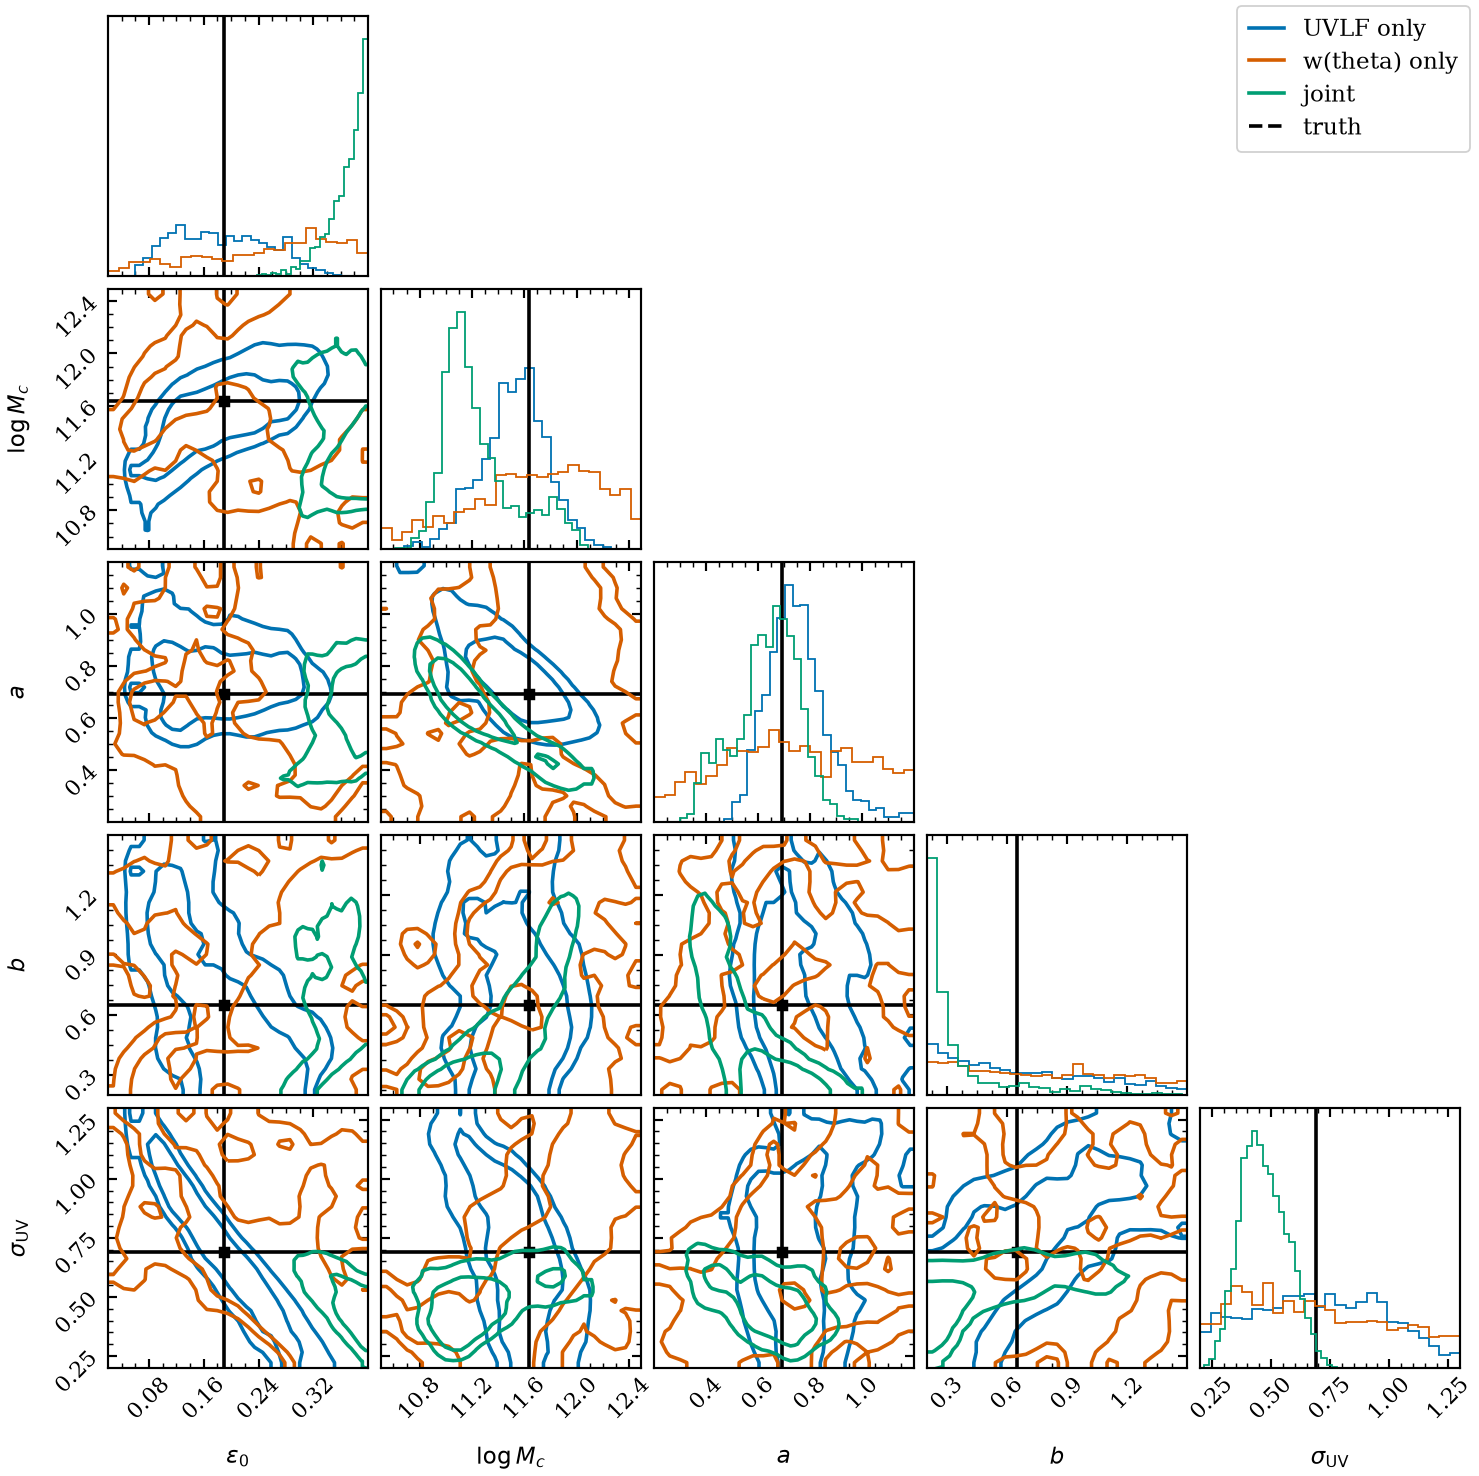

In [60]:
import corner

truth_vec = [truth[n] for n in result_uvlf.names]
labels = [r"$\epsilon_0$", r"$\log M_c$", r"$a$", r"$b$", r"$\sigma_{\rm UV}$"]

colors = {"UVLF only": "0072B2", "w(theta) only": "D55E00", "joint": "009E73"}
order = ["UVLF only", "w(theta) only", "joint"]

fig = None
ck = dict(bins=25, smooth=1.0, plot_datapoints=False, plot_density=False,
          levels=(0.68, 0.95), labels=labels)
for name in order:
    c = "#" + colors[name]
    fig = corner.corner(
        results[name].samples, fig=fig, color=c,
        truths=truth_vec if fig is None else None,
        truth_color="k", hist_kwargs=dict(density=True, color=c), **ck)

# Legend via proxy handles.
from matplotlib.lines import Line2D
handles = [Line2D([0], [0], color="#" + colors[n], lw=2, label=n) for n in order]
handles.append(Line2D([0], [0], color="k", lw=2, ls="--", label="truth"))
fig.legend(handles=handles, loc="upper right", fontsize=13,
           frameon=True, bbox_to_anchor=(0.98, 0.98))
plt.show()

### $1\sigma$ marginal uncertainties

For each case and parameter we report the half-width of the 16th&ndash;84th
percentile interval, $\tfrac{1}{2}(q_{84} - q_{16})$, and the offset of the
median from the truth in units of that width (the "pull"). A well-behaved fit
recovers truth within $\sim\!1$&ndash;$2\sigma$.

In [61]:
def sigma_table(results, truth):
    names = list(results.values())[0].names
    rows = []
    for pname in names:
        row = {"param": pname}
        for case, res in results.items():
            s = res.summary()[pname]
            sig = 0.5 * (s["q84"] - s["q16"])
            pull = (s["q50"] - truth[pname]) / sig if sig > 0 else np.nan
            row[f"{case} sigma"] = sig
            row[f"{case} pull"] = pull
        rows.append(row)
    return names, rows


names, rows = sigma_table(results, truth)

# Print a plain table (pandas optional).
try:
    import pandas as pd
    df = pd.DataFrame(rows).set_index("param")
    from IPython.display import display
    display(df.style.format("{:.3f}"))
except Exception:
    hdr = ["param"] + [k for k in rows[0].keys() if k != "param"]
    print("  ".join(f"{h:>16}" for h in hdr))
    for r in rows:
        print("  ".join(
            f"{r['param']:>16}" if h == "param" else f"{r[h]:>16.3f}"
            for h in hdr))

           param   UVLF only sigma    UVLF only pull  w(theta) only sigma  w(theta) only pull       joint sigma        joint pull
            eps0             0.076            -0.113             0.110             0.780             0.026             7.225
           logMc             0.248            -0.418             0.503             0.155             0.274            -1.720
               a             0.109             0.450             0.288             0.107             0.127            -0.306
               b             0.394            -0.128             0.431             0.218             0.166            -2.321
        sigma_UV             0.299             0.021             0.341            -0.117             0.101            -2.264


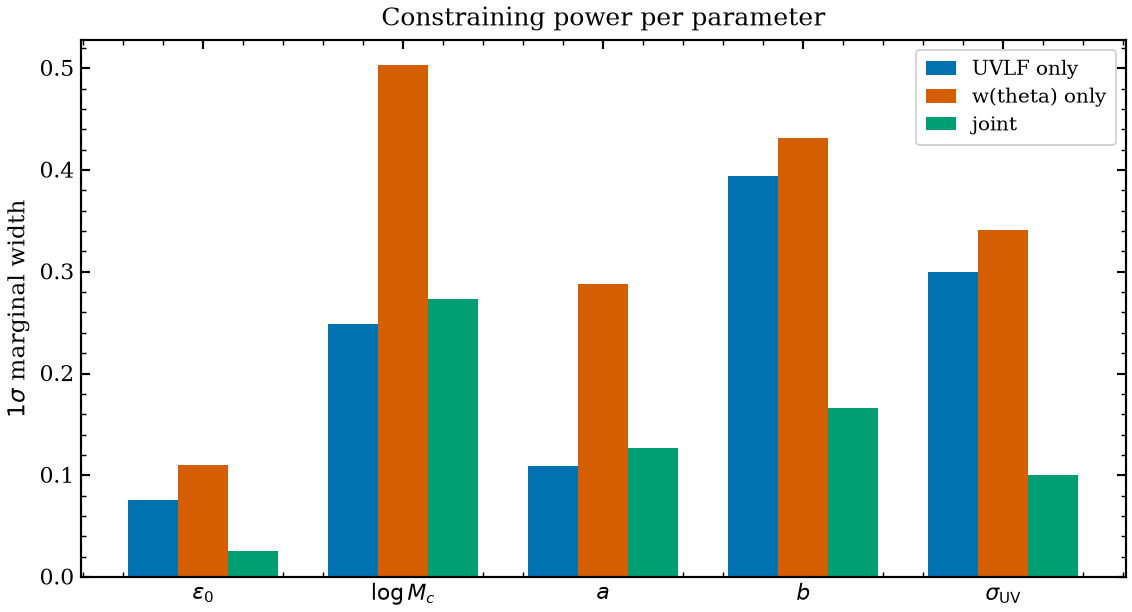

In [62]:
# A compact bar chart of the 1-sigma widths per parameter per case.
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(names))
width = 0.25
for i, case in enumerate(order):
    sig = [0.5 * (results[case].summary()[p]["q84"]
                  - results[case].summary()[p]["q16"]) for p in names]
    ax.bar(x + (i - 1) * width, sig, width,
           color="#" + colors[case], label=case)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel(r"$1\sigma$ marginal width")
ax.set_title("Constraining power per parameter")
ax.legend()
plt.tight_layout()
plt.show()

### Discussion: degeneracy directions and why the joint fit wins

Read the corner plot along its degeneracy axes:

- **UVLF only** constrains the abundance/shape of the SFE well
  ($\epsilon_0$, the slopes $a$, $b$, and the scatter $\sigma_{\rm UV}$), but is
  comparatively loose on the characteristic mass $\log M_c$: many
  $(\epsilon_0, \log M_c)$ combinations produce almost the same number counts,
  so those two run along a **banana-shaped degeneracy**.
- **$w(\theta)$ only** measures the *bias*, hence the host **halo mass**, so it
  pins $\log M_c$ tightly &mdash; but it barely constrains the SFE
  normalisation $\epsilon_0$ or the scatter, because clustering amplitude is
  nearly blind to how bright a given halo's galaxy is. Its contours are elongated
  in the SFE-amplitude direction, roughly orthogonal to the UVLF's.
- **Joint** intersects the two: the clustering constraint on $\log M_c$ slices
  through the UVLF banana, and the UVLF's grip on $\epsilon_0$ tightens what
  clustering leaves open. The joint contour is therefore **smaller than either
  parent** and, crucially, smaller than their naive overlap because the
  degeneracy directions are complementary.

This is the quantitative case for joint UVLF + clustering analyses of Euclid's
high-$z$ samples: neither probe alone breaks the SFE&ndash;halo-mass degeneracy,
but together they do.

*(With the short live chains the contours are noisy; the effect is robust but
sharper with longer `NSTEPS`.)*

## 7. Nested sampling and the Bayesian evidence (dynesty)

`emcee` gives us the posterior; **nested sampling** (`dynesty`) additionally
gives the **Bayesian evidence** $\log Z = \log \int \mathcal{L}(\theta)\,
\pi(\theta)\,d\theta$. We run it on the **UVLF-only** likelihood (cheap) both to
cross-check the posterior against `emcee` and to obtain $\log Z$. The run is
bounded by `maxcall` so it cannot overrun the session.

In [43]:
pset_dy, like_dy = build_likelihood("uvlf")
t0 = time.time()
result_dy = DynestySampler(pset_dy, like_dy).run(
    nlive=DYNESTY_NLIVE, maxcall=DYNESTY_MAXCALL,
    print_progress=False, seed=SEED)
print(f"dynesty wall time {time.time() - t0:.1f} s")
print(f"log Z = {result_dy.log_evidence:.2f} "
      f"+/- {result_dy.log_evidence_err:.2f}")

dynesty wall time 59.2 s
log Z = 95.81 +/- 1.42


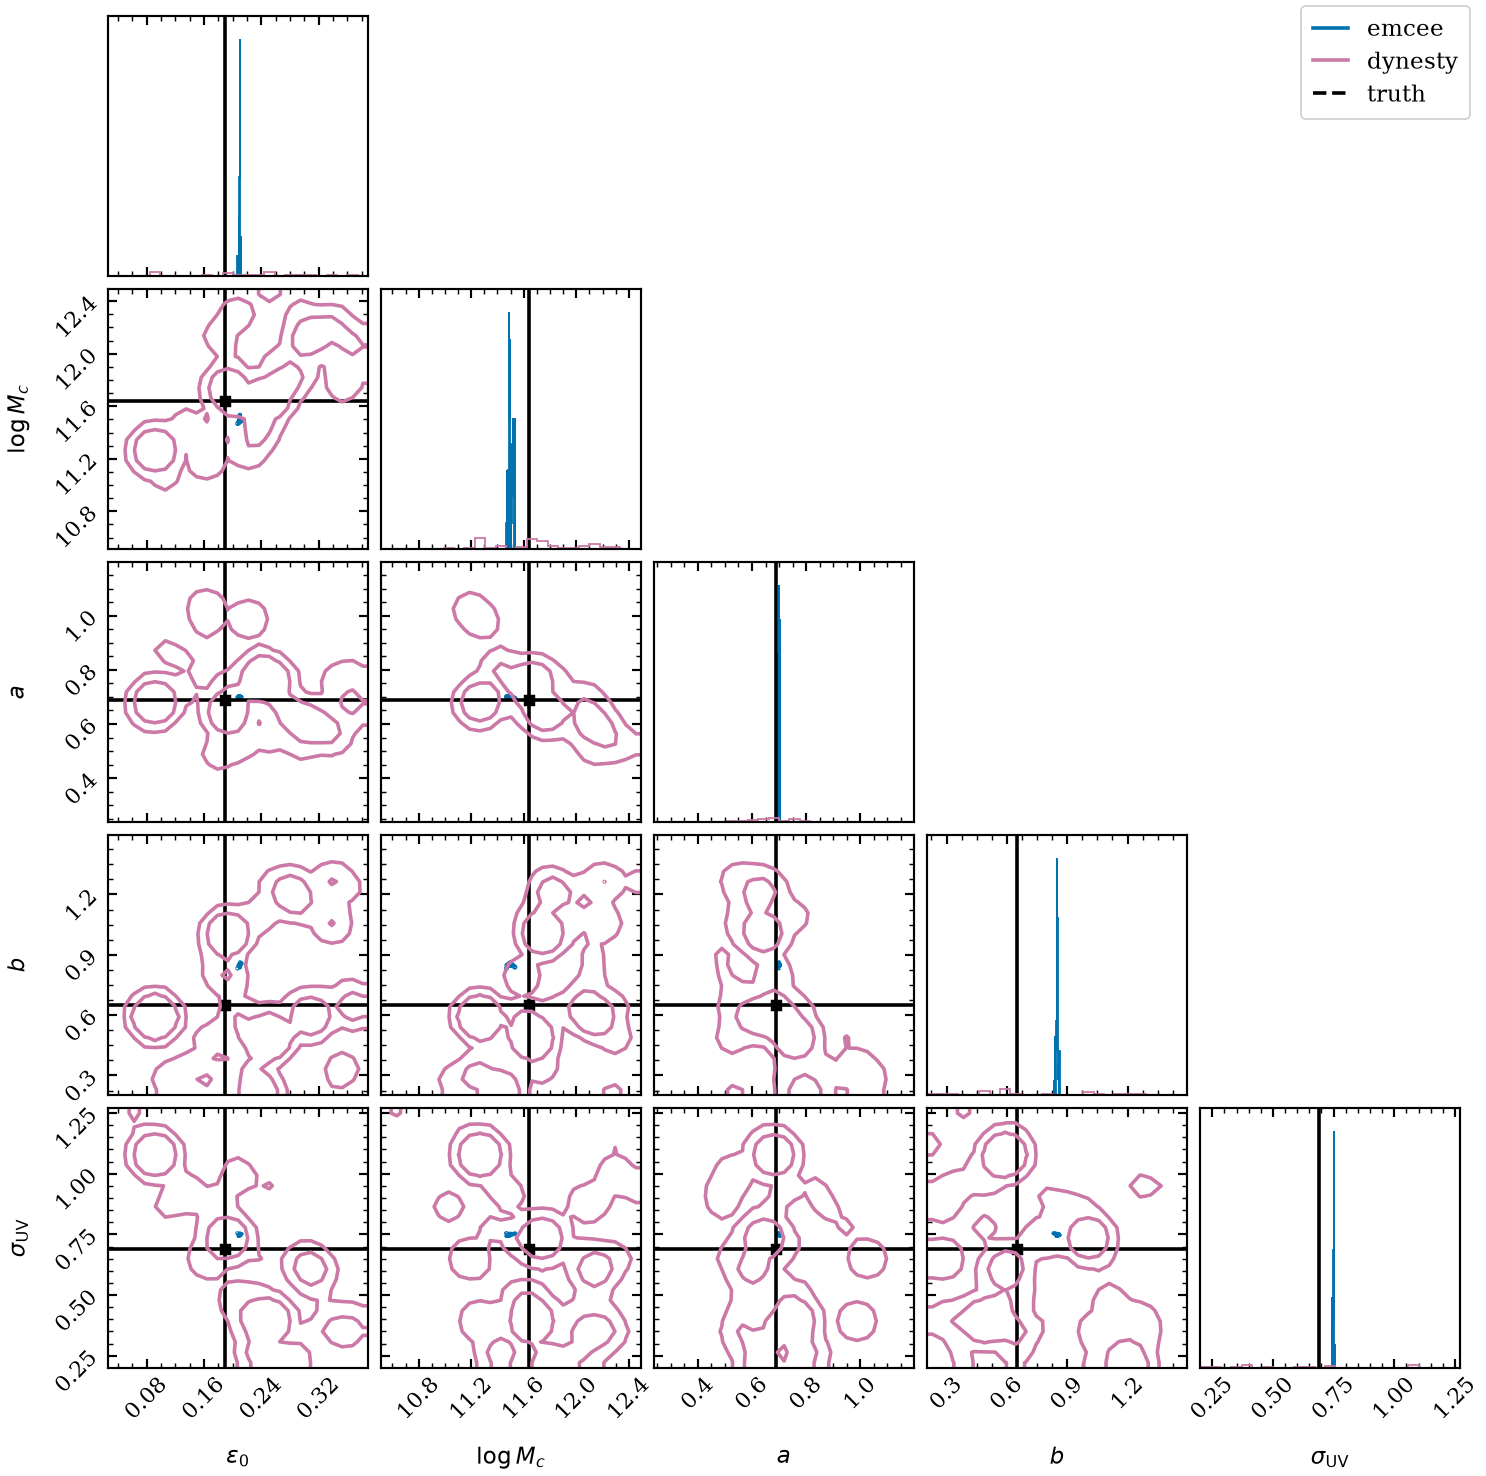

In [44]:
# Cross-check: dynesty (weighted) vs emcee posteriors on the UVLF-only case.
fig = corner.corner(result_uvlf.samples, color="#0072B2", labels=labels,
                    truths=truth_vec, truth_color="k",
                    bins=25, smooth=1.0, plot_datapoints=False,
                    plot_density=False, levels=(0.68, 0.95),
                    hist_kwargs=dict(density=True, color="#0072B2"))
fig = corner.corner(result_dy.samples, fig=fig, color="#CC79A7",
                    weights=result_dy.weights,
                    bins=25, smooth=1.0, plot_datapoints=False,
                    plot_density=False, levels=(0.68, 0.95),
                    hist_kwargs=dict(density=True, color="#CC79A7"))
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([0], [0], color="#0072B2", lw=2, label="emcee"),
                    Line2D([0], [0], color="#CC79A7", lw=2, label="dynesty"),
                    Line2D([0], [0], color="k", lw=2, ls="--", label="truth")],
           loc="upper right", fontsize=13, bbox_to_anchor=(0.98, 0.98))
plt.show()

The two posteriors agree, which is a reassuring cross-check that the sampler
choice is not driving the result.

**What is the evidence *for*?** $\log Z$ is the probability of the *data* under
the *model*, marginalised over all parameters. It is the currency of **model
comparison on the same data**: the difference $\Delta \log Z$ between two models
(e.g. "does adding a satellite term or an extra SFE break improve the fit enough
to justify the extra parameters?") is a Bayes factor that automatically penalises
complexity. A single $\log Z$ in isolation is not meaningful &mdash; it only has
teeth as a *difference* between competing models fit to identical data.

## 8. Wrap-up and extensions

**Recap.** On a controlled injection&ndash;recovery test we saw the
complementarity in action: the UVLF constrains the SFE amplitude/shape,
clustering constrains the host halo mass, and the **joint** fit is tighter than
either alone because their degeneracy directions are near-orthogonal. This is
the quantitative motivation for joint UVLF + clustering analyses of Euclid's
high-$z$ galaxy samples.

**Where to go next with the same API:**

- **Redshift evolution.** Swap `ModelParametrization("fixed_z", ...)` for
  `("evolution", ...)`, name the parameters after the evolution coefficients
  (`d_eps0_dz`, `C_eps0`, ...), and include datasets at several redshifts to fit
  the redshift *trend* jointly. `GaussianLikelihood` already loops over bins.
- **Real data + full covariance.** `Dataset.clustering(..., cov=w_cov)` accepts a
  full covariance matrix (e.g. jackknife/bootstrap for clustering); the Cholesky
  factor is cached once. Here we used a diagonal `sigma` as a tutorial
  simplification.
- **Number-density term.** Add a `Dataset.number_density(...)` observable to
  anchor the overall normalisation alongside the UVLF and clustering.
- **Model selection with dynesty.** Fit competing models and compare their
  $\log Z$ to decide, e.g., whether the data warrant extra SFE freedom.

**Pointers:**
- `docs/inference.md` &mdash; the module design document (architecture,
  the two redshift modes, parallelism, extension points).
- `examples/fit_shuntov25.py` &mdash; the production fitting script. Run it as a
  script (not in a notebook) for long, robust chains with clean multiprocessing
  under the `if __name__ == "__main__"` guard.

Thanks &mdash; questions welcome!